# Masked Autoencoder


<b> Objective: </b>
Predict held-out elements with a masked autoencoder, as a neural alternative to the tree models

----------------------

<i><b>Author: </b> Salvador Palma <br>
<b>Institution: </b> Copenhagen University </i>

A network sees a sample's elements with some of them hidden and learns to reconstruct them.
Unlike the tree models, **one model per fold covers every element**: at test time the target is
hidden and its reconstruction is the prediction.

Same data, folds and targets as notebook 2, so results drop into the same tables. Two configurations:

| config | input | compare with |
|---|---|---|
| `Chemistry` | the sample's own elements | HGB baseline |
| `Chemistry + Neighbours` | plus the mean of every element over the k nearest training samples | HGB KNN C |

### Imports

In [10]:
import sys
import os
COLAB_SESSION = True

DRIVE_PATH = ""
if COLAB_SESSION:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DRIVE_PATH = "/content/drive/MyDrive/UCPH/POOCS/"
    sys.path.insert(0, DRIVE_PATH)

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.neighbors import NearestNeighbors

from GreenlandUtils import lonlatToUTM24N, MostCommonElements, Printable

torch.manual_seed(42)
np.random.seed(42)

#Small enough for CPU; a GPU runtime is picked up automatically if available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}   device: {DEVICE}")

Mounted at /content/drive
torch 2.11.0+cu128   device: cuda


### Setup

In [11]:
DATA_TYPE = "Stream Sediment"
MERGE_TYPE = "Mean Merge"
SOURCE_CSV = "stream-sediment"

DATA_PATH = f"Data/{DATA_TYPE}/{MERGE_TYPE}/"
RESULTS_PATH = f"Results/{DATA_TYPE}/{MERGE_TYPE}/"
os.makedirs(f"{DRIVE_PATH}{RESULTS_PATH}", exist_ok=True)

MIN_COVERAGE = 10
MIN_TARGET_COVERAGE = 1000

df = pd.read_csv(f"{DRIVE_PATH}{DATA_PATH}Data.csv", delimiter=";", low_memory=False)
with open(f"{DRIVE_PATH}Data/{SOURCE_CSV}.json") as f:
    schema = json.load(f)

elementCols = [c for c in df.columns if c not in schema["metaCols"] + schema["physicalCols"]]
coverage = df[elementCols].notna().sum()
elementCols = [c for c in elementCols if coverage[c] >= MIN_COVERAGE]
elementsToTrain = [c for c in elementCols if coverage[c] >= MIN_TARGET_COVERAGE]
mostCommonElements = [e for e, _ in MostCommonElements(df, elementCols, top_n=10)]

with open(f"{DRIVE_PATH}{DATA_PATH}5-Fold.kfold") as f:
    kfold = json.load(f)
#Row positions rather than labels, since everything below works on arrays
folds = [(df.index.get_indexer(kfold[k]["train"]), df.index.get_indexer(kfold[k]["test"]))
         for k in sorted(kfold, key=int)]


def LoadResults(baseName: str) -> dict:
    path = f"{DRIVE_PATH}{RESULTS_PATH}{baseName}.json"
    if not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)


def SaveResults(results: dict, baseName: str):
    with open(f"{DRIVE_PATH}{RESULTS_PATH}{baseName}.json", "w") as f:
        json.dump(results, f, indent=4)


def AggregateFolds(kfoldResults: dict) -> dict:
    """Same format as the other notebooks, plus the stopping epoch."""
    aggregated = {}
    for element, folds_ in kfoldResults.items():
        valid = [s for s in folds_.values() if s["r2"] is not None and not np.isnan(s["r2"])]
        if not valid:
            aggregated[element] = { "r2": None, "mae": None }
            continue
        aggregated[element] = {
            "r2": float(np.mean([s["r2"] for s in valid])),
            "r2_std": float(np.std([s["r2"] for s in valid])),
            "mae": float(np.mean([s["mae"] for s in valid])),
            "epochs": float(np.mean([s["epochs"] for s in valid])),
        }
    return aggregated


print(f"Samples: {len(df)}   Elements: {len(elementCols)}   Targets: {len(elementsToTrain)}   Folds: {len(folds)}")

Analyzing Elements: 100%|██████████| 87/87 [00:00<00:00, 5901.45it/s]

Samples: 17463   Elements: 87   Targets: 71   Folds: 5


### Inputs

Each element becomes two channels: the standardised value (zero when missing) and a present flag,
so the network can tell "average" from "not measured". Scaling uses training rows only.

Neighbour channels are variant C from notebook 2: the mean of every element over the `NEIGHBOUR_K`
nearest **training** samples, co-located samples excluded. They are never masked, and they include
the target's own neighbour mean, exactly as KNN C does.

In [12]:
NEIGHBOUR_K = 20


def Standardise(values: np.ndarray, trainPos: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        centre = np.nanmean(values[trainPos], axis=0)
        spread = np.nanstd(values[trainPos], axis=0)
    spread = np.where((spread == 0) | ~np.isfinite(spread), 1.0, spread)
    centre = np.where(np.isfinite(centre), centre, 0.0)

    present = np.isfinite(values).astype(np.float32)
    scaled = np.where(np.isfinite(values), (values - centre) / spread, 0.0).astype(np.float32)
    return scaled, present, centre, spread


def NeighbourMeans(trainPos: np.ndarray, k: int = NEIGHBOUR_K) -> np.ndarray:
    """Variant C: per-element mean over the k nearest training samples, co-location excluded."""

    x, y = lonlatToUTM24N(df["Longitude"].to_numpy(float), df["Latitude"].to_numpy(float))
    coords = np.column_stack([x, y])

    padding = int(df.groupby(["Longitude", "Latitude"]).size().max())
    tree = NearestNeighbors(n_neighbors=min(k + padding, len(trainPos))).fit(coords[trainPos])
    distances, positions = tree.kneighbors(coords)
    neighbourPos = trainPos[positions]

    rejected = (neighbourPos == np.arange(len(df))[:, None]) | (distances == 0)
    distances = np.where(rejected, np.inf, distances)
    order = np.argsort(distances, axis=1)[:, :k]
    neighbourPos = np.take_along_axis(neighbourPos, order, axis=1)
    usable = np.isfinite(np.take_along_axis(distances, order, axis=1))

    values = df[elementCols].to_numpy(float)[neighbourPos]
    values[~usable] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(values, axis=1)


def BuildInputs(trainPos: np.ndarray, useNeighbours: bool) -> dict:
    raw = df[elementCols].to_numpy(float)
    scaled, present, centre, spread = Standardise(raw, trainPos)

    if useNeighbours:
        nScaled, nPresent, _, _ = Standardise(NeighbourMeans(trainPos), trainPos)
        extra = np.hstack([nScaled, nPresent])
    else:
        extra = np.zeros((len(df), 0), dtype=np.float32)

    tensor = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    return { "values": tensor(scaled), "present": tensor(present), "extra": tensor(extra),
             "raw": raw, "centre": centre, "spread": spread }

### The Network

A plain MLP: `[values, present flags, neighbour channels]` in, one value per element out.

In [13]:
class MaskedAutoencoder(nn.Module):

    def __init__(self, nElements: int, extraDim: int, hiddenDim: int = 256, layers: int = 3, dropout: float = 0.1):
        super().__init__()
        dims = [2 * nElements + extraDim] + [hiddenDim] * layers
        blocks = []
        for inDim, outDim in zip(dims[:-1], dims[1:]):
            blocks += [nn.Linear(inDim, outDim), nn.GELU(), nn.Dropout(dropout)]
        self.body = nn.Sequential(*blocks)
        self.head = nn.Linear(hiddenDim, nElements)

    def forward(self, values, present, extra):
        return self.head(self.body(torch.cat([values, present, extra], dim=1)))

### Training

Each batch hides a random `MASK_RATE` share of the **measured** entries and the loss is computed
only on those — the model is never rewarded for copying what it can see.

A tenth of the training rows is held out with a fixed mask to pick the stopping epoch. Patience is
generous: the GNN runs showed a tight patience stopping well before the validation minimum.

In [14]:
MASK_RATE = 0.25
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
MAX_EPOCHS = 2000
PATIENCE = 150


def MaskedLoss(model, inputs: dict, rows: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    values, present, extra = inputs["values"][rows], inputs["present"][rows], inputs["extra"][rows]
    keep = 1.0 - mask
    prediction = model(values * keep, present * keep, extra)
    return ((prediction - values) ** 2 * mask).sum() / mask.sum().clamp(min=1)


def TrainFold(inputs: dict, trainPos: np.ndarray, verbose: bool = False) -> tuple[nn.Module, dict]:

    generator = torch.Generator().manual_seed(42)
    shuffled = trainPos[torch.randperm(len(trainPos), generator=generator).numpy()]
    validRows = torch.tensor(shuffled[: len(shuffled) // 10], device=DEVICE)
    fitRows = torch.tensor(shuffled[len(shuffled) // 10:], device=DEVICE)

    #A fixed validation mask, so validation loss is comparable between epochs
    validMask = ((torch.rand(inputs["present"][validRows].shape, generator=generator).to(DEVICE) < MASK_RATE)
                 * inputs["present"][validRows])

    model = MaskedAutoencoder(len(elementCols), inputs["extra"].shape[1]).to(DEVICE)
    optimiser = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

    best, bestState, bestEpoch, waited = float("inf"), None, 0, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        for batch in fitRows[torch.randperm(len(fitRows), device=DEVICE)].split(BATCH_SIZE):
            mask = (torch.rand(inputs["present"][batch].shape, device=DEVICE) < MASK_RATE) * inputs["present"][batch]
            optimiser.zero_grad()
            MaskedLoss(model, inputs, batch, mask).backward()
            optimiser.step()

        model.eval()
        with torch.no_grad():
            validLoss = float(MaskedLoss(model, inputs, validRows, validMask))

        if validLoss < best - 1e-5:
            best, bestEpoch, waited = validLoss, epoch, 0
            bestState = { key: value.clone() for key, value in model.state_dict().items() }
        else:
            waited += 1
            if waited >= PATIENCE:
                break
        if verbose and epoch % 50 == 0:
            print(f"   epoch {epoch:>4}  valid {validLoss:.4f}  best {best:.4f} @ {bestEpoch}  "
                  f"patience {waited}/{PATIENCE}", flush=True)

    model.load_state_dict(bestState)
    return model, { "best_epoch": bestEpoch, "stopped_epoch": epoch,
                    "hit_max_epochs": epoch == MAX_EPOCHS - 1, "valid_loss": best }

### Scoring

For each target, the test samples where it was measured get that one element hidden (value and
flag zeroed) and everything else visible — the same information the tree models get. Predictions
are converted back to log10 units, so MAE is comparable with the other notebooks.

In [15]:
def ScoreFold(model: nn.Module, inputs: dict, testPos: np.ndarray, targets: list[str], epochs: int) -> dict:
    model.eval()
    scores = {}
    for target in targets:
        column = elementCols.index(target)
        rows = testPos[np.isfinite(inputs["raw"][testPos, column])]
        if len(rows) < 5:
            scores[target] = { "r2": None, "mae": None, "epochs": epochs }
            continue

        index = torch.tensor(rows, device=DEVICE)
        values = inputs["values"][index].clone()
        present = inputs["present"][index].clone()
        values[:, column] = 0.0
        present[:, column] = 0.0

        with torch.no_grad():
            scaled = model(values, present, inputs["extra"][index])[:, column].cpu().numpy()

        prediction = scaled * inputs["spread"][column] + inputs["centre"][column]
        truth = inputs["raw"][rows, column]
        total = ((truth - truth.mean()) ** 2).sum()
        scores[target] = {
            "r2": float(1 - ((truth - prediction) ** 2).sum() / total) if total > 0 else None,
            "mae": float(np.abs(truth - prediction).mean()),
            "epochs": epochs,
        }
    return scores

### Running

One model per fold per configuration. Results are cached under the same naming as notebook 2 — the
full target set with the `_Cov1000` suffix, and the ten best-covered elements without — plus a
training log with the stopping epochs. Delete the files to retrain.

In [16]:
CONFIGS = {
    "Chemistry":              { "useNeighbours": False, "baseName": "MaskedAutoencoder_KFold" },
    "Chemistry + Neighbours": { "useNeighbours": True,  "baseName": f"MaskedAutoencoder_KFold_Neighbours_k{NEIGHBOUR_K}" },
}

results = {}
for name, config in CONFIGS.items():
    base = config["baseName"]
    results[name] = LoadResults(f"{base}_Cov1000")
    if results[name] is not None:
        print(f"{name:<24} cached")
        continue

    raw = { target: {} for target in elementsToTrain }
    log = []
    for foldIdx, (trainPos, testPos) in enumerate(folds):
        print(f"{name} - fold {foldIdx + 1}/{len(folds)}", flush=True)
        inputs = BuildInputs(trainPos, config["useNeighbours"])
        model, info = TrainFold(inputs, trainPos, verbose=True)
        log.append({ "fold": foldIdx, **info })
        for target, score in ScoreFold(model, inputs, testPos, elementsToTrain, info["stopped_epoch"] + 1).items():
            raw[target][foldIdx] = score
        print(f"{name:<24} fold {foldIdx}: best epoch {info['best_epoch']}, stopped {info['stopped_epoch']}"
              f"{'  (HIT MAX_EPOCHS)' if info['hit_max_epochs'] else ''}")

    results[name] = AggregateFolds(raw)
    SaveResults(results[name], f"{base}_Cov1000")
    #The top-10 file is a subset of the same run, so it lines up with the unsuffixed tree results
    SaveResults({ e: results[name][e] for e in mostCommonElements }, base)
    SaveResults({ "folds": log }, f"{base}_TrainingLog")

Chemistry - fold 1/5
   epoch    0  valid 0.4636  best 0.4636 @ 0  patience 0/150
   epoch   50  valid 0.2126  best 0.2104 @ 49  patience 1/150
   epoch  100  valid 0.1953  best 0.1913 @ 95  patience 5/150
   epoch  150  valid 0.1875  best 0.1844 @ 149  patience 1/150
   epoch  200  valid 0.1805  best 0.1801 @ 189  patience 11/150
   epoch  250  valid 0.1797  best 0.1795 @ 232  patience 18/150
   epoch  300  valid 0.1836  best 0.1780 @ 271  patience 29/150
   epoch  350  valid 0.1805  best 0.1776 @ 349  patience 1/150
   epoch  400  valid 0.1811  best 0.1776 @ 349  patience 51/150
   epoch  450  valid 0.1811  best 0.1760 @ 447  patience 3/150
   epoch  500  valid 0.1778  best 0.1747 @ 456  patience 44/150
   epoch  550  valid 0.1789  best 0.1747 @ 456  patience 94/150
   epoch  600  valid 0.1806  best 0.1747 @ 456  patience 144/150
Chemistry                fold 0: best epoch 456, stopped 606
Chemistry - fold 2/5
   epoch    0  valid 0.5096  best 0.5096 @ 0  patience 0/150
   epoch   50

### Comparison

Against the cached tree results on the same targets and folds.

In [17]:
REFERENCES = {
    "HGB chemistry":   "HistGradientBoosting_KFold_FeatureSet_Chemistry_Cov1000",
    "RF chemistry":    "RandomForest_KFold_Cov1000",
    "HGB KNN C (k=20)": "HistGradientBoosting_KFold_KNN_C_ExcludingColocation_Cov1000",
}


def MeanR2(result: dict, elements: list[str]) -> float:
    return float(np.mean([result[e]["r2"] for e in elements]))


everything = { f"MAE {name}": r for name, r in results.items() }
everything.update({ name: r for name, r in ((n, LoadResults(b)) for n, b in REFERENCES.items()) if r is not None })

#Only targets every model scored, so means are comparable
common = [e for e in elementsToTrain if all(r.get(e, {}).get("r2") is not None for r in everything.values())]
baseline = MeanR2(everything["HGB chemistry"], common) if "HGB chemistry" in everything else np.nan

printable = Printable()
printable.title(f"Mean R2 over {len(common)} targets")
for name, r in everything.items():
    printable.add(name, f"{MeanR2(r, common):.4f}   vs HGB chemistry {MeanR2(r, common) - baseline:+.4f}")
printable.flush()

=================== Mean R2 over 71 targets ===================
MAE Chemistry:                0.8421   vs HGB chemistry -0.0255
MAE Chemistry + Neighbours:   0.8449   vs HGB chemistry -0.0227
HGB chemistry:                0.8676   vs HGB chemistry +0.0000
RF chemistry:                 0.8587   vs HGB chemistry -0.0089
HGB KNN C (k=20):             0.8801   vs HGB chemistry +0.0125


=== MAE Chemistry vs HGB chemistry: wins on 3/71 ===


,MAE Chemistry,HGB chemistry,difference
Mn %,0.855,0.934,-0.079
S %,0.596,0.672,-0.076
Tl ppm,0.752,0.822,-0.070
L.o.i. wt%,0.861,0.919,-0.058
Zr ppm,0.808,0.863,-0.055
Pb ppm,0.640,0.641,-0.002
Ho ppm,0.972,0.973,-0.001
Zn ppm,0.785,0.781,0.004
Au ppb,0.132,0.128,0.004
Pr ppm,0.952,0.945,0.008


=== MAE Chemistry + Neighbours vs HGB KNN C (k=20): wins on 0/71 ===


,MAE Chemistry + Neighbours,HGB KNN C (k=20),difference
Mn %,0.852,0.937,-0.084
Zr ppm,0.786,0.865,-0.080
Tl ppm,0.756,0.831,-0.075
S %,0.616,0.689,-0.073
As ppm,0.596,0.667,-0.071
Cu ppm,0.816,0.834,-0.017
Er ppm,0.963,0.979,-0.016
Ho ppm,0.957,0.972,-0.015
Sum wt%,0.968,0.978,-0.010
Pr ppm,0.941,0.946,-0.005


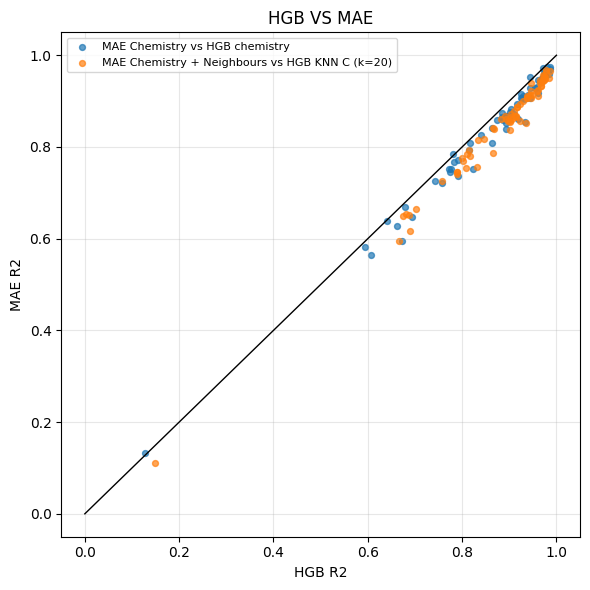

In [22]:
def PerElement(model: str, reference: str) -> pd.DataFrame:
    frame = pd.DataFrame({
        model: { e: everything[model][e]["r2"] for e in common },
        reference: { e: everything[reference][e]["r2"] for e in common },
    })
    frame["difference"] = frame[model] - frame[reference]
    return frame.sort_values("difference")


for model, reference in [("MAE Chemistry", "HGB chemistry"), ("MAE Chemistry + Neighbours", "HGB KNN C (k=20)")]:
    if model in everything and reference in everything:
        frame = PerElement(model, reference)
        print(f"=== {model} vs {reference}: wins on {(frame.difference > 0).sum()}/{len(frame)} ===")
        display(pd.concat([frame.head(5), frame.tail(5)]).round(3))


fig, ax = plt.subplots(figsize=(6, 6))
for model, reference in [("MAE Chemistry", "HGB chemistry"), ("MAE Chemistry + Neighbours", "HGB KNN C (k=20)")]:
    if model in everything and reference in everything:
        frame = PerElement(model, reference)
        ax.scatter(frame[reference], frame[model], s=18, alpha=0.7, label=f"{model} vs {reference}")
ax.plot([0, 1], [0, 1], color="black", linewidth=1)
ax.set_xlabel("HGB R2")
ax.set_ylabel("MAE R2")
ax.set_title("HGB VS MAE")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [19]:
for name, config in CONFIGS.items():
    log = LoadResults(f"{config['baseName']}_TrainingLog")
    if log:
        print(f"{name}: " + ", ".join(f"fold {f['fold']} best {f['best_epoch']}/stopped {f['stopped_epoch']}"
                                      + (" MAX" if f["hit_max_epochs"] else "") for f in log["folds"]))

Chemistry: fold 0 best 456/stopped 606, fold 1 best 694/stopped 844, fold 2 best 589/stopped 739, fold 3 best 453/stopped 603, fold 4 best 657/stopped 807
Chemistry + Neighbours: fold 0 best 413/stopped 563, fold 1 best 338/stopped 488, fold 2 best 222/stopped 372, fold 3 best 408/stopped 558, fold 4 best 326/stopped 476
